In [ ]:
# Netflix Exploratory Data Analysis (EDA)

In [1]:
#Load the Netflix dataset into a Pandas DataFrame.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
#Display the first five records to understand the dataset.

df = pd.read_csv("netflix_titles_nov_2019.csv")

In [3]:
#Check the number of rows and columns in the dataset.

df.head()

,show_id,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,type
0,81193313,Chocolate,NaN,"Ha Ji-won, Yoon Kye-sang, Jang Seung-jo, Kang ...",South Korea,"November 30, 2019",2019,TV-14,1 Season,"International TV Shows, Korean TV Shows, Roman...",Brought together by meaningful meals in the pa...,TV Show
1,81197050,Guatemala: Heart of the Mayan World,"Luis Ara, Ignacio Jaunsolo",Christian Morales,NaN,"November 30, 2019",2019,TV-G,67 min,"Documentaries, International Movies","From Sierra de las Minas to Esquipulas, explor...",Movie
2,81213894,The Zoya Factor,Abhishek Sharma,"Sonam Kapoor, Dulquer Salmaan, Sanjay Kapoor, ...",India,"November 30, 2019",2019,TV-14,135 min,"Comedies, Dramas, International Movies",A goofy copywriter unwittingly convinces the I...,Movie
3,81082007,Atlantics,Mati Diop,"Mama Sane, Amadou Mbow, Ibrahima Traore, Nicol...","France, Senegal, Belgium","November 29, 2019",2019,TV-14,106 min,"Dramas, Independent Movies, International Movies","Arranged to marry a rich man, young Ada is cru...",Movie
4,80213643,Chip and Potato,NaN,"Abigail Oliver, Andrea Libman, Briana Buckmast...","Canada, United Kingdom",NaN,2019,TV-Y,2 Seasons,Kids' TV,"Lovable pug Chip starts kindergarten, makes ne...",TV Show


In [4]:
#Display all the column names in the dataset.

df.shape

(5837, 12)

In [5]:
#Explore the dataset structure, data types, and missing values.

df.columns

Index(['show_id', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'type'],
      dtype='object')

In [6]:
#Generate statistical summary for numerical columns.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5837 entries, 0 to 5836
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       5837 non-null   int64 
 1   title         5837 non-null   object
 2   director      3936 non-null   object
 3   cast          5281 non-null   object
 4   country       5410 non-null   object
 5   date_added    5195 non-null   object
 6   release_year  5837 non-null   int64 
 7   rating        5827 non-null   object
 8   duration      5837 non-null   object
 9   listed_in     5837 non-null   object
 10  description   5837 non-null   object
 11  type          5837 non-null   object
dtypes: int64(2), object(10)
memory usage: 547.3+ KB


In [7]:
#Identify missing values in each column.

df.describe()

,show_id,release_year
count,5.837000e+03,5837.000000
mean,7.730079e+07,2013.688539
std,9.479777e+06,8.419088
min,2.698800e+05,1925.000000
25%,8.004520e+07,2013.000000
50%,8.016353e+07,2016.000000
75%,8.024188e+07,2018.000000
max,8.122720e+07,2020.000000


In [8]:
#Calculate the total number of missing values.

df.isnull().sum()

show_id            0
title              0
director        1901
cast             556
country          427
date_added       642
release_year       0
rating            10
duration           0
listed_in          0
description        0
type               0
dtype: int64

In [9]:
#Sort missing values from highest to lowest.

df.isnull().sum().sum()

np.int64(3536)

In [10]:
#Check for duplicate records in the dataset.

df.isnull().sum().sort_values(ascending=False)

director        1901
date_added       642
cast             556
country          427
rating            10
title              0
show_id            0
release_year       0
duration           0
listed_in          0
description        0
type               0
dtype: int64

In [11]:
#Remove duplicate records from the dataset.

df.duplicated().sum()

np.int64(0)

In [12]:
#Analyze the distribution of Movies and TV Shows.

df.drop_duplicates(inplace=True)

In [13]:
#Visualize the distribution of Movies and TV Shows.

df["type"].value_counts()


type
Movie      3939
TV Show    1898
Name: count, dtype: int64

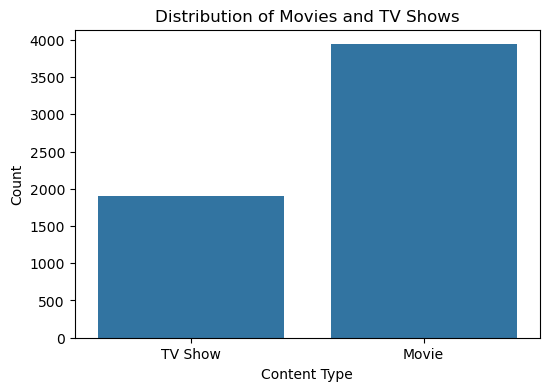

In [14]:
#Identify the top 10 countries producing Netflix content.

plt.figure(figsize=(6,4))
sns.countplot(x="type", data=df)

plt.title("Distribution of Movies and TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")

plt.show()

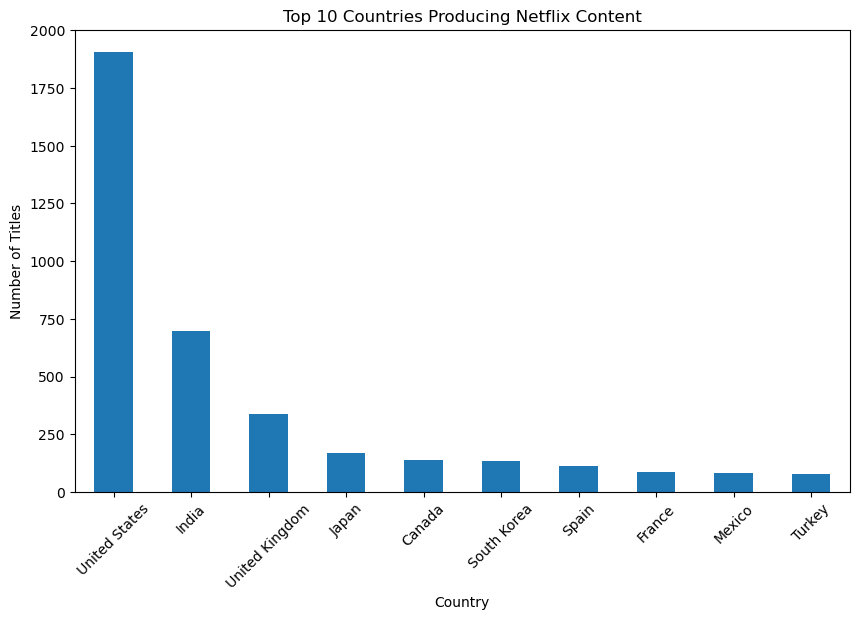

In [15]:
#Analyze the top 10 genres available on Netflix.

top_countries = df["country"].value_counts().head(10)

plt.figure(figsize=(10,6))
top_countries.plot(kind="bar")

plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Country")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.show()

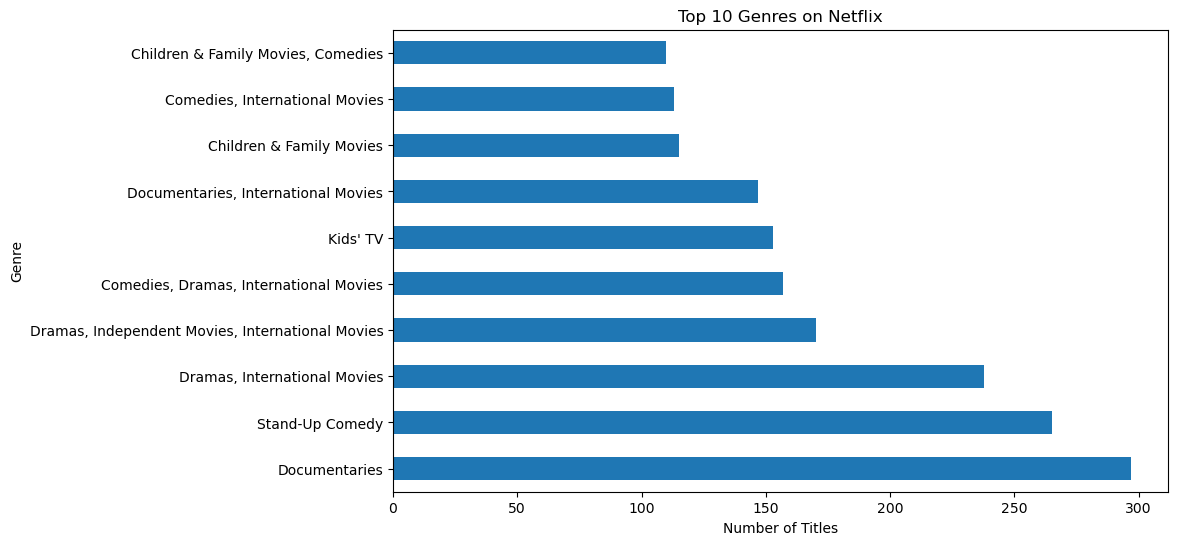

In [16]:
#Visualize the distribution of Netflix content ratings.

top_genres = df["listed_in"].value_counts().head(10)

plt.figure(figsize=(10,6))
top_genres.plot(kind="barh")

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

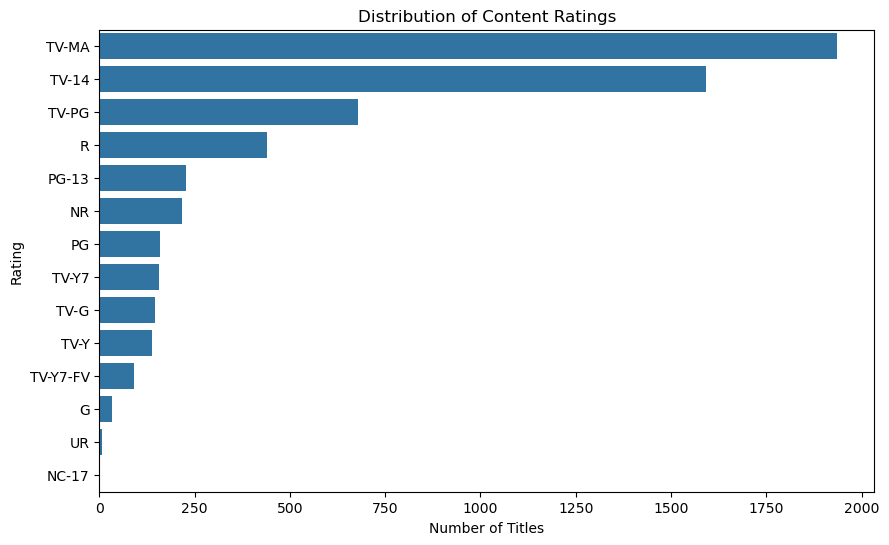

In [17]:
#Analyze the distribution of content release years.

plt.figure(figsize=(10,6))

sns.countplot(
    y="rating",
    data=df,
    order=df["rating"].value_counts().index
)

plt.title("Distribution of Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")

plt.show()

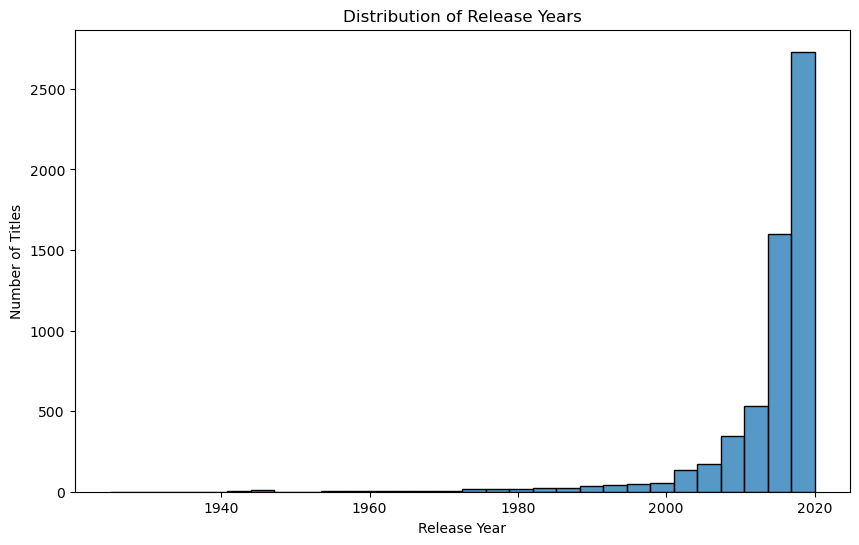

In [18]:
#Analyze how Netflix expanded its content library over the years.

plt.figure(figsize=(10,6))

sns.histplot(df["release_year"], bins=30)

plt.title("Distribution of Release Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

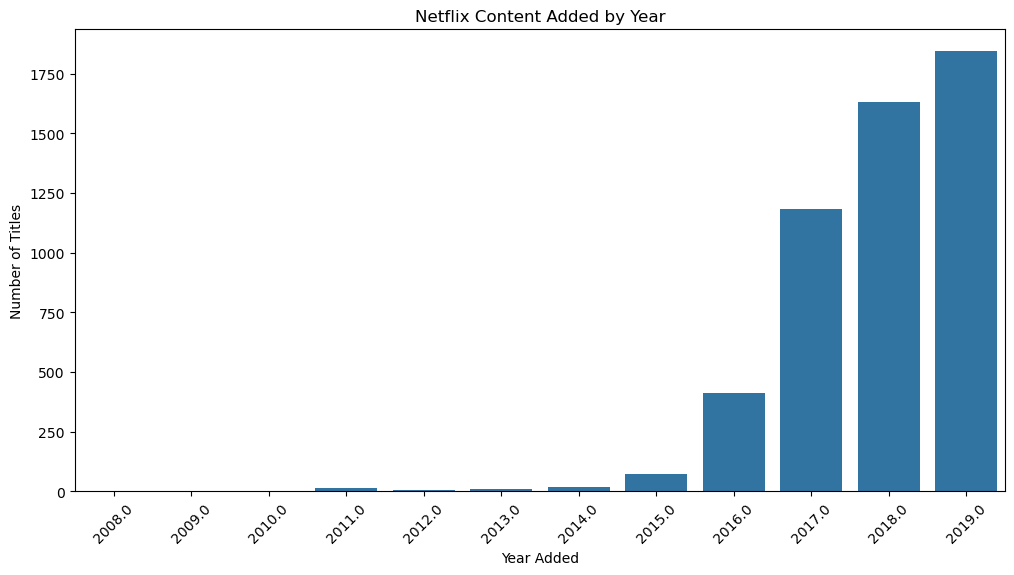

In [21]:
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")
df["year_added"] = df["date_added"].dt.year

plt.figure(figsize=(12,6))

sns.countplot(
    x="year_added",
    data=df,
    order=sorted(df["year_added"].dropna().unique())
)

plt.xticks(rotation=45)

plt.title("Netflix Content Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")

plt.show()